### 이진 분류 실습 문제 1

## Iris Dataset
: 붓꽃의 꽃받침과 꽃잎의 측정값을 이용해 Setosa와 Versicolor 두 품종을 구분하는 이진 분류 모델 구현.

- 전체 데이터: 150개
- 이번 실습에서 사용할 데이터: 100개
- 입력 특징: 4개
- 정답: 꽃 품종 (Setosa 또는 Versicolor)

| 열 이름 | 의미 | 설명 |
|:---:|:---:|:---|
| `sepal_length` | 꽃받침 길이 | 꽃받침의 길이, cm |
| `sepal_width` | 꽃받침 너비 | 꽃받침의 너비, cm |
| `petal_length` | 꽃잎 길이 | 꽃잎의 길이, cm |
| `petal_width` | 꽃잎 너비 | 꽃잎의 너비, cm |
| `species` | 꽃 품종 | `setosa`, `versicolor`, `virginica` |


#### Step1. 데이터 불러오기 및 전처리

**실습 조건**
- `setosa`와 `versicolor` 두 품종만 사용하고 `virginica`는 제외한다.
- `setosa`는 클래스 0, `versicolor`는 클래스 1로 변환한다.
- 4개의 측정값을 입력값(X), 품종 레이블을 정답(y)으로 사용한다.
- 학습 데이터와 테스트 데이터를 8:2 비율로 분리한다.
- 학습 데이터의 평균과 표준편차를 이용해 입력 특징을 표준화한다.

In [2]:
import pandas as pd 
import torch 
from torch.utils.data import TensorDataset, DataLoader
from torch import nn, optim
import matplotlib.pyplot as plt 
import numpy as np
import random

In [3]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

columns = ['sepal_length','sepal_width','petal_length','petal_width','species']
df = pd.read_csv(url)

print(df.head())
print('데이터의 크기 :', df.shape)
print('종별 데이터 개수 : ')
print(df['species'].value_counts().sort_index())
# Setosa와 Versicolor만 선택

df = df[df["species"].isin(["setosa", "versicolor"])].copy()

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
데이터의 크기 : (150, 5)
종별 데이터 개수 : 
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
# 입력데이터(x)와 정답데이터(y)의 분리
X = torch.tensor(df[['sepal_length','sepal_width','petal_length','petal_width']].values, dtype=torch.float32)
y_values = df['species'].map({'setosa':0, 'versicolor':1}).values

y = torch.tensor(y_values, dtype = torch.float32).reshape(-1,1)

# 클래스별로 학습/테스트 데이터를 나누기
torch.manual_seed(42) 
train_indices = []
test_indices = []

for species_value in [0,1] : 
    species_indices = []

    for i in range(len(y)) :
        if y[i].item() == species_value : 
            species_indices.append(i)

    # 순서를 무작위로 섞기
    random.shuffle(species_indices)

    # 학습 80%, 테스트 20% 분리
    split = int(len(species_indices)*0.8)

    train_indices.extend(species_indices[:split])
    test_indices.extend(species_indices[split:])

for species_value in [0,1] : 
    species_indices = torch.where(y.squeeze() == species_value)[0]
    species_indices = species_indices[torch.randperm(len(species_indices))]

    split = int(len(species_indices)*0.8)

    train_indices.extend(species_indices[:split])
    test_indices.extend(species_indices[split:])

print(len(train_indices))
print(len(test_indices))

train_indices = torch.tensor(train_indices)[torch.randperm(len(train_indices))]
test_indices = torch.tensor(test_indices)[torch.randperm(len(test_indices))]

X_train = X[train_indices]
X_test = X[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

mean = X_train.mean(dim=0)
std = X_train.std(dim=0).clamp(min = 1e-8)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print('X_train :', X_train.shape)
print('y_train :', y_train.shape)
print('X_test :', X_test.shape)
print('y_test :', y_test.shape)


160
40
X_train : torch.Size([160, 4])
y_train : torch.Size([160, 1])
X_test : torch.Size([40, 4])
y_test : torch.Size([40, 1])


In [5]:
BATCH_SIZE = 32

train_DS = TensorDataset(X_train, y_train)
test_DS = TensorDataset(X_test, y_test)

train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle = True)
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle = False)

N = len(train_DL.dataset)
print(N)

160


#### Step2. 모델 만들기

**목표:** Banknote Authentication 실습에서 사용한 MLP 구조로 붓꽃 품종을 분류한다.

- 입력 노드: 4개
- 은닉층: 100개 노드
- 출력 노드: 1개
- 출력 활성화 함수: Sigmoid
- 예측값이 0.5 이상이면 클래스 1, 0.5 미만이면 클래스 0

In [6]:
class MLP(nn.Module) : 
    def __init__(self) : 
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(4,100),
                                    nn.Sigmoid(),
                                    nn.Linear(100,1),
                                    nn.Sigmoid()
                                    )
    def forward(self, x)  : 
        x = self.linear(x)
        return x
    
model = MLP()

#### STEP 3. 모델 학습시키기

- Optimizer: SGD
- Loss function: BCELoss
- 학습률(LR): 0.1
- Epoch: 100
- Batch size: 16 또는 32

In [7]:
LR = 1e-1
EPOCH = 100

optimizer = optim.SGD(model.parameters(), lr = LR)
criterion = nn.BCELoss()

loss_history = []

model.train()
for ep in range(EPOCH) : 
    rloss = 0

    for x_batch, y_batch in train_DL : 
        y_hat = model(x_batch)

        loss = criterion(y_hat, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        rloss += loss.item()* x_batch.shape[0]

    epoch_loss = rloss / N
    loss_history.append(epoch_loss)

    print(f'Epoch : {ep+1}, train Loss : {epoch_loss : .4f}')
    print('-'*20)


Epoch : 1, train Loss :  0.6204
--------------------
Epoch : 2, train Loss :  0.4901
--------------------
Epoch : 3, train Loss :  0.3928
--------------------
Epoch : 4, train Loss :  0.3274
--------------------
Epoch : 5, train Loss :  0.2767
--------------------
Epoch : 6, train Loss :  0.2402
--------------------
Epoch : 7, train Loss :  0.2076
--------------------
Epoch : 8, train Loss :  0.1833
--------------------
Epoch : 9, train Loss :  0.1613
--------------------
Epoch : 10, train Loss :  0.1449
--------------------
Epoch : 11, train Loss :  0.1311
--------------------
Epoch : 12, train Loss :  0.1197
--------------------
Epoch : 13, train Loss :  0.1100
--------------------
Epoch : 14, train Loss :  0.1009
--------------------
Epoch : 15, train Loss :  0.0935
--------------------
Epoch : 16, train Loss :  0.0873
--------------------
Epoch : 17, train Loss :  0.0814
--------------------
Epoch : 18, train Loss :  0.0760
--------------------
Epoch : 19, train Loss :  0.0716
----

<function matplotlib.pyplot.grid(visible: 'bool | None' = None, which: "Literal['major', 'minor', 'both']" = 'major', axis: "Literal['both', 'x', 'y']" = 'both', **kwargs) -> 'None'>

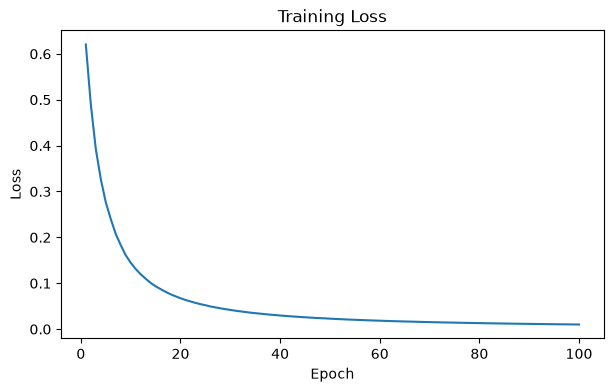

In [8]:
plt.figure(figsize = (7,4))
plt.plot(range(1, EPOCH +1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.grid

#### Step4. 모델 테스트하기

- Sigmoid 출력값에 임계값 0.5를 적용해 클래스를 예측.
- 전체 테스트 데이터 중 정답을 맞힌 개수와 Accuracy(%)를 출력.

In [9]:
model.eval()

correct = 0
total = 0
with torch.no_grad() :
    for x_batch, y_batch in test_DL : 
        y_hat = model(x_batch)
        pred = (y_hat >=0.5).float()

        correct += (pred == y_batch).sum().item()
        total += y_batch.numel()

accuracy = correct / total* 100
print(f'Test accuracy : {correct}/{total}  ({accuracy:.1f}%)')

Test accuracy : 40/40  (100.0%)


#### Step5. 테스트 결과 시각화

- 실제 클래스와 예측 클래스를 이용해 2×2 혼동행렬(Confusion Matrix)을 작성.
- 실제 클래스별 예측 확률 분포를 히스토그램으로 나타내시오.
- 혼동행렬의 행은 실제 클래스, 열은 예측 클래스로 표시하시오.
- 클래스 0과 클래스 1이 무엇을 의미하는지 그래프에 표시하시오.

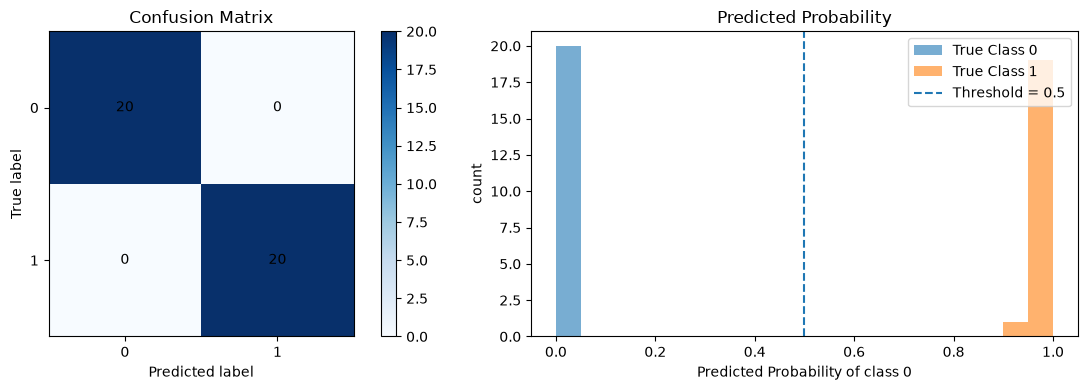

In [10]:
model.eval()

y_true_all = [] # 정답 전체
y_prob_all = [] # 예측 전체 

with torch.no_grad() :
    for x_batch, y_batch in test_DL : 
        y_hat = model(x_batch)

        y_true_all.append(y_batch.numpy().reshape(-1))
        y_prob_all.append(y_hat.numpy().reshape(-1))

# 배치별로 나누어 저장했던 실제 정답 배열들을 하나로 합친다음, 데이터 타입 정수형으로 변환 
y_true = np.concatenate(y_true_all).astype(int)
y_prob = np.concatenate(y_prob_all)
y_pred = (y_prob >= 0.5). astype(int)

# 혼동행렬 : 행은 실제 클래스, 열은 예측 클래스 
cm = np.zeros((2,2), dtype = int)
for true, pred in zip(y_true, y_pred) : ## zip : 같은 요소끼리 묶어주는 것 
    cm[true, pred] += 1

fig, axes = plt.subplots(1, 2, figsize=(12,4))

im = axes[0].imshow(cm, cmap = 'Blues')
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted label')
axes[0].set_ylabel('True label')
axes[0].set_xticks([0,1], labels = ['0','1'])
axes[0].set_yticks([0,1], labels = ['0','1'])

for i in range(2) : 
    for j in range(2) : 
        axes[0].text(j, i, cm[i,j], ha = 'center', va = 'center')

fig.colorbar(im, ax = axes[0])

# 클래스별 예측 확률 분포 
bins = np.linspace(0,1,21)
axes[1].hist(y_prob[y_true == 0], bins = bins, alpha = 0.6, label = 'True Class 0')
axes[1].hist(y_prob[y_true == 1], bins = bins, alpha = 0.6, label = 'True Class 1')
axes[1].axvline(0.5, linestyle = '--', label='Threshold = 0.5')
axes[1].set_title('Predicted Probability')
axes[1].set_xlabel('Predicted Probability of class 0')
axes[1].set_ylabel('count')
axes[1].legend()
plt.tight_layout()

plt.show()

#### STEP 6. 파라미터 개수 확인